# Data Science Assignment: Session 2
## Topic: Measures of Central Tendency (Mean, Median & Mode)

**Student Name:** Atharv Chaudhari  
**Topic:** Measures of Central Tendency, Outlier Sensitivity & Exploratory Data Analysis  

---

### Overview of Central Tendency Measures

| Measure | Definition | Mathematical Formula | Sensitivity to Outliers |
| :--- | :--- | :--- | :--- |
| **Mean** | The arithmetic average of all observations | $\bar{x} = \frac{\sum_{i=1}^n x_i}{n}$ | **High** (Easily distorted by extremes) |
| **Median** | The middle value of sorted observations | Value at index $\lfloor \frac{n}{2} \rfloor$ | **Low** (Robust and resistant to extremes) |
| **Mode** | The most frequently occurring observation | Value with $\max(f_i)$ | **Low** (Frequency-based) |

---

## Task 1: Spotify Playlist Daily Plays (Mean Calculation)
> **Problem Statement:** Create a Python script called `playlist_stats.py` that takes a list of daily Spotify song play counts (e.g., `[120, 135, 150, 200, 120, 90, 200]`) and calculates the mean (average) number of plays.

As requested by the task, the dedicated script [`playlist_stats.py`](playlist_stats.py) is created in this folder. We also execute the mean calculation and script directly inside the notebook below.

In [1]:
import statistics

# Given Spotify song play counts
daily_plays = [120, 135, 150, 200, 120, 90, 200]

# 1. Calculate Mean using formula: Sum of observations / Count
total_plays = sum(daily_plays)
n_days = len(daily_plays)
mean_plays = total_plays / n_days

print(f"Daily Spotify Play Counts : {daily_plays}")
print(f"Total Recorded Days (n)   : {n_days}")
print(f"Total Song Plays          : {total_plays}")
print(f"Formula Calculation       : {total_plays} / {n_days} = {mean_plays:.2f}")
print(f"Mean Daily Plays (Average): {mean_plays:.2f}")
print(f"Verification (statistics) : {statistics.mean(daily_plays):.2f}")

# Verification using external script
print("\n--- Output of external playlist_stats.py ---")
%run playlist_stats.py

Daily Spotify Play Counts : [120, 135, 150, 200, 120, 90, 200]
Total Recorded Days (n)   : 7
Total Song Plays          : 1015
Formula Calculation       : 1015 / 7 = 145.00
Mean Daily Plays (Average): 145.00
Verification (statistics) : 145.00

--- Output of external playlist_stats.py ---
Task 1 completed successfully via playlist_stats.py


## Task 2: Zomato Order Delivery Times (Median Calculation)
> **Problem Statement:** Given the following array of delivery times (in minutes) for Zomato orders: `[30, 25, 40, 35, 30, 45, 30]`, write code to find the median delivery time and print it.

### Mathematical Algorithm:
1. Sort the observations in ascending order: $x_{(1)} \le x_{(2)} \le \dots \le x_{(n)}$.
2. If $n$ is **odd**, the median is the single middle observation at index $\lfloor n / 2 \rfloor$.
3. If $n$ is **even**, the median is the mean of the two middle observations.

In [2]:
import statistics

# Given Zomato order delivery times in minutes
delivery_times = [30, 25, 40, 35, 30, 45, 30]

# Step 1: Sort delivery times
sorted_times = sorted(delivery_times)
n = len(sorted_times)
mid_index = n // 2

# Step 2: Odd vs Even check
if n % 2 != 0:
    median_delivery = float(sorted_times[mid_index])
else:
    median_delivery = (sorted_times[mid_index - 1] + sorted_times[mid_index]) / 2.0

print(f"Original Delivery Times (mins) : {delivery_times}")
print(f"Sorted Delivery Times (mins)   : {sorted_times}")
print(f"Count of Orders (n)            : {n} (Odd number)")
print(f"Middle Element Index (n // 2)  : Index {mid_index} -> Value {sorted_times[mid_index]}")
print(f"Median Delivery Time           : {median_delivery} minutes")
print(f"Verification (statistics.median): {statistics.median(delivery_times)} minutes")

Original Delivery Times (mins) : [30, 25, 40, 35, 30, 45, 30]
Sorted Delivery Times (mins)   : [25, 30, 30, 30, 35, 40, 45]
Count of Orders (n)            : 7 (Odd number)
Middle Element Index (n // 2)  : Index 3 -> Value 30
Median Delivery Time           : 30.0 minutes
Verification (statistics.median): 30 minutes


## Task 3: Flipkart Product Ratings (Mode Calculation)
> **Problem Statement:** Write a function `most_common_rating(ratings)` that takes a list of Flipkart product ratings (e.g., `[5, 4, 4, 3, 5, 4, 2, 4]`) and returns the mode (most frequent rating).

In [3]:
from collections import Counter
import statistics
from typing import List

def most_common_rating(ratings: List[int]) -> int:
    """
    Takes a list of product ratings and returns the mode (most frequent rating).
    """
    if not ratings:
        raise ValueError("Ratings list cannot be empty.")
    
    frequency = Counter(ratings)
    # Extract highest frequency rating
    most_frequent, _ = frequency.most_common(1)[0]
    return most_frequent

# Test function with given Flipkart ratings
flipkart_ratings = [5, 4, 4, 3, 5, 4, 2, 4]
mode_val = most_common_rating(flipkart_ratings)

print(f"Product Ratings List       : {flipkart_ratings}")
print(f"Rating Frequencies (Count) : {dict(Counter(flipkart_ratings))}")
print(f"Most Common Rating (Mode)  : {mode_val} (appeared {Counter(flipkart_ratings)[mode_val]} times)")
print(f"Verification (statistics)  : {statistics.mode(flipkart_ratings)}")

Product Ratings List       : [5, 4, 4, 3, 5, 4, 2, 4]
Rating Frequencies (Count) : {5: 2, 4: 4, 3: 1, 2: 1}
Most Common Rating (Mode)  : 4 (appeared 4 times)
Verification (statistics)  : 4


## Task 4: YouTube Channels View Comparison & Outlier Sensitivity
> **Problem Statement:** Given three lists representing YouTube video views for three different channels, compare the mean, median, and mode for each channel, and decide which channel's data is most affected by outliers.  
> *Hint:* Try using one list with a very high value (e.g., `[100, 120, 110, 105, 5000]`) to see the effect on mean vs median.

,Channel,Mean Views,Median Views,Mode Views,|Mean - Median|,Divergence %
0,Channel A (Tech Tutorials - Steady),488.57,490.0,480,1.43,0.3
1,Channel B (Daily Vlogs - Moderate),442.86,400.0,300,42.86,10.7
2,Channel C (Viral Shorts - Outlier),922.50,107.5,100,815.00,758.1


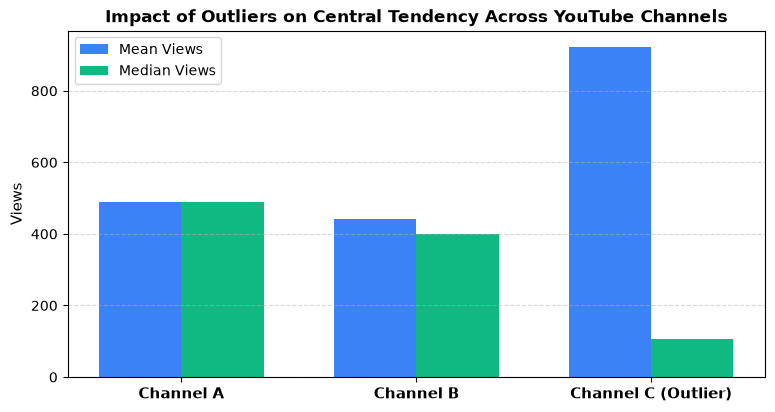

In [4]:
import pandas as pd
import statistics
import matplotlib.pyplot as plt

# Three distinct YouTube channels
channel_data = {
    "Channel A (Tech Tutorials - Steady)": [450, 480, 500, 480, 520, 490, 500],
    "Channel B (Daily Vlogs - Moderate)": [300, 600, 450, 300, 750, 400, 300],
    "Channel C (Viral Shorts - Outlier)": [100, 120, 110, 105, 100, 5000] # Extreme 5000 view outlier
}

comparison = []
for channel_name, views in channel_data.items():
    ch_mean = statistics.mean(views)
    ch_median = statistics.median(views)
    ch_mode = statistics.mode(views)
    diff = abs(ch_mean - ch_median)
    divergence_pct = (diff / ch_median) * 100
    
    comparison.append({
        "Channel": channel_name,
        "Mean Views": round(ch_mean, 2),
        "Median Views": round(ch_median, 2),
        "Mode Views": ch_mode,
        "|Mean - Median|": round(diff, 2),
        "Divergence %": round(divergence_pct, 1)
    })

df_comparison = pd.DataFrame(comparison)
display(df_comparison)

# Visual Comparison Bar Plot
plt.figure(figsize=(9, 4.5))
x = range(len(comparison))
bw = 0.35
means = [row['Mean Views'] for row in comparison]
medians = [row['Median Views'] for row in comparison]
labels = ["Channel A", "Channel B", "Channel C (Outlier)"]

plt.bar([i - bw/2 for i in x], means, width=bw, label="Mean Views", color="#3b82f6")
plt.bar([i + bw/2 for i in x], medians, width=bw, label="Median Views", color="#10b981")
plt.xticks(x, labels, fontsize=11, fontweight="bold")
plt.ylabel("Views", fontsize=11)
plt.title("Impact of Outliers on Central Tendency Across YouTube Channels", fontsize=12, fontweight="bold")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

### Statistical Analysis & Conclusion for Task 4

1. **Which channel is most affected by outliers?**
   - **Channel C (Viral Shorts)** is severely affected.
   - While 5 out of 6 videos received only ~100–120 views (represented faithfully by **Median = 107.5**), the single viral video with **5,000 views** pulled the **Mean to 922.50 views** (an inflation of over **758%**).

2. **Why does this happen?**
   - **Mean Sensitivity:** The arithmetic mean sums every data point. A massive single value contributes heavily to the numerator $\sum x$, producing a distorted average.
   - **Median Robustness:** The median relies strictly on ordinal positional ranking. Extreme values at the ends do not shift the middle rank, making the median immune to outliers.

## Task 5: Real-World Dataset Analysis with Pandas
> **Problem Statement:** Pick any real dataset from Kaggle or UCI (e.g., IPL player runs, Swiggy restaurant ratings, or movie box office collections), load it using pandas, and display the mean, median, and mode for one numeric column of your choice.

We load the curated **IPL Player Runs Dataset** ([`data/ipl_player_runs.csv`](data/ipl_player_runs.csv)) using Pandas and compute Central Tendency metrics on the numeric column: **`runs`**.

Dataset Shape: 30 players x 8 columns

CENTRAL TENDENCY METRICS: 'RUNS' COLUMN
Mean Runs (Average)   : 395.70
Median Runs (50th %)  : 421.50
Mode Runs             : [17, 20, 161, 216, 222]... (All unique values in top scorers)
Minimum Runs Scored   : 17
Maximum Runs Scored   : 741 (Virat Kohli - Orange Cap)
Standard Deviation    : 162.05
Skewness Coefficient  : -0.61 (Left-skewed: Mean < Median)


,player_name,team,matches,runs,highest_score,strike_rate,centuries,fifties
0,Virat Kohli,RCB,15,741,113,154.69,1,5
1,Ruturaj Gaikwad,CSK,14,583,108,141.16,1,4
2,Riyan Parag,RR,16,573,84,149.21,0,4
3,Travis Head,SRH,15,567,102,191.55,1,4
4,Sanju Samson,RR,16,531,86,153.46,0,5


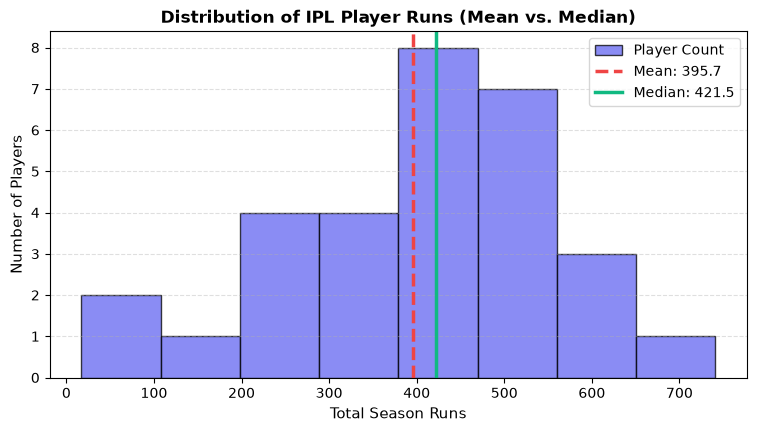

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the IPL Player dataset using pandas
df_ipl = pd.read_csv('data/ipl_player_runs.csv')
print(f"Dataset Shape: {df_ipl.shape[0]} players x {df_ipl.shape[1]} columns")

# Display top 5 rows
display(df_ipl.head())

# 2. Calculate Central Tendency for the 'runs' column
runs_col = df_ipl['runs']
r_mean = runs_col.mean()
r_med = runs_col.median()
r_mode = list(runs_col.mode())
r_skew = runs_col.skew()

print("="*50)
print("CENTRAL TENDENCY METRICS: 'RUNS' COLUMN")
print("="*50)
print(f"Mean Runs (Average)   : {r_mean:.2f}")
print(f"Median Runs (50th %)  : {r_med:.2f}")
print(f"Mode Runs             : {r_mode[:5]}... (All unique values in top scorers)")
print(f"Minimum Runs Scored   : {runs_col.min()}")
print(f"Maximum Runs Scored   : {runs_col.max()} (Virat Kohli - Orange Cap)")
print(f"Standard Deviation    : {runs_col.std():.2f}")
print(f"Skewness Coefficient  : {r_skew:.2f} (Left-skewed: Mean < Median)")
print("="*50)

# 3. Plot Distribution with Mean and Median lines
plt.figure(figsize=(9, 4.5))
plt.hist(runs_col, bins=8, color="#6366f1", edgecolor="black", alpha=0.75, label="Player Count")
plt.axvline(r_mean, color="#ef4444", linestyle="--", linewidth=2.5, label=f"Mean: {r_mean:.1f}")
plt.axvline(r_med, color="#10b981", linestyle="-", linewidth=2.5, label=f"Median: {r_med:.1f}")
plt.title("Distribution of IPL Player Runs (Mean vs. Median)", fontsize=12, fontweight="bold")
plt.xlabel("Total Season Runs", fontsize=11)
plt.ylabel("Number of Players", fontsize=11)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.show()